# 08 · HistGradientBoosting (not in the handbook; strongest model in the first draft)
Handles missing values itself and needs no scaling or one-hot encoding, so it uses the cleaned
DataFrame with categories encoded as integers.

In [1]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

d = load_prepared()
x_train, x_val, x_test = d["x_train"], d["x_val"], d["x_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
feature_names = d["feature_names"]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

data = d["data"]
X_tr, X_va, X_te = data.iloc[d["indices_train"]], data.iloc[d["indices_val"]], data.iloc[d["indices_test"]]
cat_cols = data.select_dtypes(exclude="number").columns.tolist()
num_cols = data.select_dtypes(include="number").columns.tolist()

def hgb_pipe(lr, leaves):
    pre = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                               encoded_missing_value=-2), cat_cols),
        ("num", "passthrough", num_cols)])
    model = HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=500,
                                           early_stopping=True, random_state=42)
    return Pipeline([("pre", pre), ("model", model)])

train (114844, 1711) | val (28712, 1711) | test (35890, 1711)


## Grid search over learning rate and tree size

In [2]:
results = []
for lr in [0.05, 0.1]:
    for leaves in [31, 63, 127]:
        m = hgb_pipe(lr, leaves).fit(X_tr, y_train)
        results.append((macro_f1(y_val, m.predict(X_va)), lr, leaves))
        print(lr, leaves, round(results[-1][0], 4))
_, lr_opt, leaves_opt = max(results, key=lambda r: r[0])
print("Optimal learning rate:", lr_opt, "| max_leaf_nodes:", leaves_opt)

0.05 31 0.676
0.05 63 0.6887
0.05 127 0.6869
0.1 31 0.644
0.1 63 0.6794
0.1 127 0.6301
Optimal learning rate: 0.05 | max_leaf_nodes: 63


## Final model: evaluate on test and save

{'model': 'HistGradientBoosting', 'accuracy': 0.6692, 'macro_F1': 0.6791, 'ordinal_MAE': 0.4708, 'within_one': 0.9009, 'EFG_recall': 0.811, 'AUC_ovr': 0.9448}


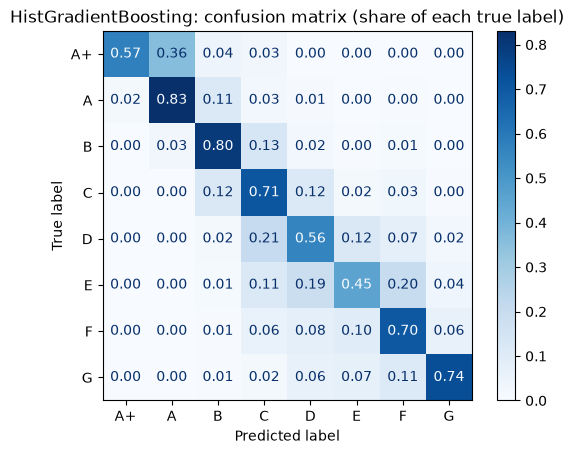

In [3]:
HGB = hgb_pipe(lr_opt, leaves_opt).fit(X_tr, y_train)
evaluate("HistGradientBoosting", HGB, X_te, y_test)
save_model(HGB, "HGB")

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

class OrdinalWrapper:
    """Regression on the label number (A+ = 0 ... G = 7), rounded back to a label."""
    def __init__(self, reg): self.reg = reg
    def predict(self, X):
        return np.array(ORDER)[np.clip(np.rint(self.reg.predict(X)), 0, 7).astype(int)]

pre = hgb_pipe(lr_opt, leaves_opt).named_steps["pre"]
reg = Pipeline([("pre", pre),
                ("model", HistGradientBoostingRegressor(learning_rate=lr_opt, max_leaf_nodes=leaves_opt,
                                                        max_iter=500, early_stopping=True, random_state=42))])
reg.fit(X_tr, pd.Series(y_train).map(TO_I))
evaluate("HGB ordinal regression", OrdinalWrapper(reg), X_te, y_test)

: 